# Import Libraries

In [55]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

# Q1
# Download Financial Data

Download 10 years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [56]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='10y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

,Date,Open,High,Low,Close
0,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
1,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
2,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
3,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
4,2016-11-07 00:00:00-05:00,97.540001,97.870003,97.220001,97.779999
...,...,...,...,...,...
2509,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
2510,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000
2511,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002
2512,2026-10-29 00:00:00-04:00,102.080002,102.449997,101.849998,102.040001


# Q1
# Construct Line Plot of HLC Data

In [57]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2016 to 2026')
fig.show()

print(df[['Open', 'High', 'Low', 'Close']].agg(['mean', 'std']))


# οι μεταβλητές OHLCV περιγραφουν την ημερήσιες χρηματιστηριακές τιμές του δολαρίου (usd), και συγκεκριμενένα: open: η τιμή ανοίγματος, low: η μικρότερη τιμή,
# high: η μεγαλύτερη τιμή, close: η τιμή κλεισίματος, και volume: ο όγκος των συναλλαγών

# Παρατηρούμε ότι οι τιμές των mean + std ειναι σχετικά κοντά μεταξύ τους. Οι mean τιμές είναι κοντά στο 99 ενω οι std τιμές είναι κοντα στο 5, συνεπώς φαίνεται να έχουμε παρόμοια διασπορά τιμών.
# Στο γράγφημα φαίνονται οι low, high, close για την τελευταία 10ετία (2016-2026)
# Το 2022 (σεπτ) φαίνεται να έχουμε μια μεγάλη αύξηση.

           Open       High        Low      Close
mean  98.800975  99.101802  98.511010  98.810947
std    4.971745   5.019362   4.915539   4.973281


# Q2

οι χρονσειρές low, high και close φαίνεται να είναι μη στάσιμες γιατί οι τιμές τους δεν κινούνται γυρώ απο έναν σταθερό μέσο όρο. Έχουν διαφορετικά επίπεδα τιμών σε διαφορετικές χρονικές περιόδους, δηλαδή αλλάζουν σε συνάρτηση με τον χρόνο, και όχι σταθερά.

# Q3

Τα τεστ adf + kpss συμφωνούν με την διαπίστωση μας ότι η χρονοσειρά είναι μη στατικής. Ενδεικτικά: adf: high: 0.332, low: 0.287, close: 0.335 > 0.05 και kpss: high, low, close: 0.01 < 0.05

In [58]:
from statsmodels.tsa.stattools import adfuller, kpss

# stats #adf and #kpss
for col in ['High', 'Low', 'Close']:
    adf = adfuller(df[col].dropna())
    kpss_result = kpss(df[col].dropna(), regression='c', nlags='auto')

    print(col)
    print('ADF p-value:', adf[1])
    print('KPSS p-value:', kpss_result[1])
    print()

High
ADF p-value: 0.33232458775021856
KPSS p-value: 0.01

Low
ADF p-value: 0.2876305280370497
KPSS p-value: 0.01

Close
ADF p-value: 0.33524128763349964
KPSS p-value: 0.01



/tmp/ipykernel_1109/2435009408.py:5: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.

/tmp/ipykernel_1109/2435009408.py:6: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.

/tmp/ipykernel_1109/2435009408.py:6: FutureWarning:

kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current 

# Q4
# Train-Test Split

Test set should start 1 time step after the end of train set.

In [59]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((1759, 5), (785, 5))

# Construct Timeframes

*   x = <x[0], x[1], x[2], ... x[H-1]>
*   y = x[H]

where x is (Open(t), High(t), Low(t), Close(t))

**Important: Past target must be included in x to achieve good accuracy**

In [60]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Verify Timeframes

In [15]:
train_df.head(5)

,Date,Open,High,Low,Close
0,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
1,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
2,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
3,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
4,2016-11-07 00:00:00-05:00,97.540001,97.870003,97.220001,97.779999


# Q5

In [61]:
# q5

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

H = [1,5,15,30]

for h in H:
    test_df = df.iloc[num_train_samples-h:]
    x_train, y_train = construct_timeframes(train_df, h)
    x_test, y_test = construct_timeframes(test_df, h)
    print('H:', h, 'Train:', x_train.shape, 'Test:', x_test.shape)

H: 1 Train: (1758, 4) Test: (755, 4)
H: 5 Train: (1754, 20) Test: (755, 20)
H: 15 Train: (1744, 60) Test: (755, 60)
H: 30 Train: (1729, 120) Test: (755, 120)


# Fit Linear Regression Model

Setting H=[1,5,15,30]

In [62]:
H = [1,5,15,30]
results = []

for h in H:
    test_df = df.iloc[num_train_samples-h:]
    x_train, y_train = construct_timeframes(train_df, h)
    x_test, y_test = construct_timeframes(test_df, h)

    model = LinearRegression()
    model.fit(x_train, y_train)

    y_pred = model.predict(x_train)
    train_mae = mean_absolute_error(y_train, y_pred)

    y_pred = model.predict(x_test)
    test_mae = mean_absolute_error(y_test, y_pred)

    results.append([h, train_mae, test_mae])

In [63]:
results_df = pd.DataFrame(results, columns=['H', 'Train MAE', 'Test MAE'])
results_df

,H,Train MAE,Test MAE
0,1,0.310161,0.309237
1,5,0.309786,0.308488
2,15,0.304228,0.316105
3,30,0.299412,0.324130


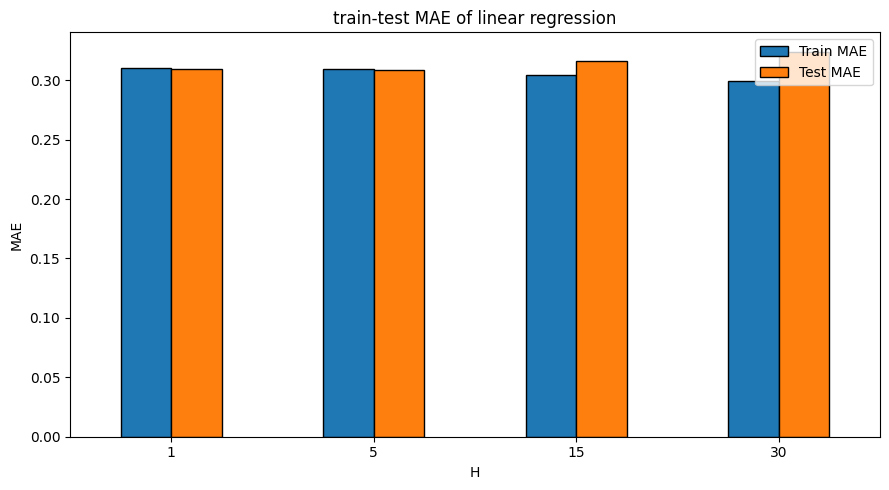

H            5.000000
Train MAE    0.309786
Test MAE     0.308488
Name: 1, dtype: float64


In [64]:
#barchart
results_df.plot(x='H', y=['Train MAE','Test MAE'], kind='bar', figsize=(9,5), edgecolor='black')
plt.title('train-test MAE of linear regression')
plt.xlabel('H')
plt.ylabel('MAE')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(results_df.loc[results_df['Test MAE'].idxmin()])

# q6


In [65]:
# h =30
history_size = 30
test_df = df.iloc[num_train_samples-history_size:]

x_train, y_train = construct_timeframes(train_df, history_size)
x_test, y_test = construct_timeframes(test_df, history_size)

model = LinearRegression()
model.fit(x_train, y_train)

train_pred = model.predict(x_train)
y_pred = model.predict(x_test)

# Visualize Predictions

In [66]:
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

# Training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train',
    line=dict(color='royalblue', width=2)
))

# Train predicted (last 30 samples)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(train_pred)[-history_size:],
    mode='lines',
    name='Train (Predicted)',
    line=dict(color='#E63946', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index - Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)



# οι τιμεές του linear regression είναι πολύ κοντά στις πραγματκές και στο train και στο test.


# Q7
# Apply Log Returns Transformation

In [67]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))
df_logr = df_logr.dropna().reset_index(drop=True)

df_logr

,Date,Open,High,Low,Close
0,2016-11-02 00:00:00-04:00,-0.006526,-0.006929,-0.004722,-0.003075
1,2016-11-03 00:00:00-04:00,-0.003792,-0.003483,-0.001442,-0.002467
2,2016-11-04 00:00:00-04:00,-0.002262,-0.001129,-0.001547,-0.000927
3,2016-11-07 00:00:00-05:00,0.003903,0.005327,0.003400,0.007288
4,2016-11-08 00:00:00-05:00,0.002151,0.001225,0.003389,0.000818
...,...,...,...,...,...
2508,2026-10-26 00:00:00-04:00,0.002065,0.002060,0.000886,0.001472
2509,2026-10-27 00:00:00-04:00,0.002453,0.003326,0.004028,0.003525
2510,2026-10-28 00:00:00-04:00,0.003327,0.000878,0.000588,-0.001271
2511,2026-10-29 00:00:00-04:00,-0.002837,-0.000390,-0.001962,-0.001469


# Convert Log Returns to Absolute Price

$lr_{t+1} = \ln(\frac{y_{t+1}}{y_{t}})$

$y_{t+1} = y_t * e^{lr_{t+1}}$

Inevitably, the first sample will be lost, as its log-return transformation cannot be defined (x[-1] does not exist).

In [68]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

In [69]:
H = [1,5,15,30]
results_logr = []

train_logr = df_logr.iloc[:num_train_samples-1]

for h in H:
    test_logr = df_logr.iloc[num_train_samples-1-h:]
    x_train, y_train = construct_timeframes(train_logr, h)
    x_test, y_test = construct_timeframes(test_logr, h)

    model = LinearRegression()
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)

    train_prices = df['Close'].iloc[h:num_train_samples-1].to_numpy()
    test_prices = df['Close'].iloc[num_train_samples-1:-1].to_numpy()

    train_actual = log_returns_to_absolute_prices(train_prices, y_train)
    test_actual = log_returns_to_absolute_prices(test_prices, y_test)
    train_pred = log_returns_to_absolute_prices(train_prices, train_pred)
    test_pred = log_returns_to_absolute_prices(test_prices, test_pred)

    train_mae = mean_absolute_error(train_actual, train_pred)
    test_mae = mean_absolute_error(test_actual, test_pred)

    results_logr.append([h, train_mae, test_mae])

results_logr_df = pd.DataFrame(results_logr, columns=['H','Train MAE','Test MAE'])
results_logr_df


comparison = results_df[['H','Test MAE']].merge(results_logr_df[['H','Test MAE']], on='H', suffixes=('_Q5','_Q7'))
comparison


# Βλέπουμε ότι το μοντέλο με Log-Returns έχει ελαφρώς μικρότερο test MAE σε όλα τα χρονικά παράθυρα σε συγκριση με το q5. Όμως, η διαφορά φαίνεται να είναι πολύ μικρή. Το καλύτερο αποτέλεσμα και στις 2 περιπτώσεις το έχουμε για h=5,
# ενώ για μεγαλλύτερα h το σφάλμα αυξάνεται κι αυτό.

,H,Test MAE_Q5,Test MAE_Q7
0,1,0.309237,0.308195
1,5,0.308488,0.307425
2,15,0.316105,0.314910
3,30,0.324130,0.323550


# Q8
# Check Whether High can Predict Close

Variables that can estimate the target variable are considered beneficial.

In [70]:
data = train_df[['Close', 'Open']]

# Computing log-returns (converting to stationary series).
data = np.log(data/data.shift(1)).dropna()

# Test up to history_size lags
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

# Extract p-values
p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
granger_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
granger_df['Significant'] = granger_df['P-value'] < 0.05
granger_df

#print(granger_df[granger_df['Significant'] == True])

# Με βάση τα αποτελέσματα παρατηρούμε ότι μονο για lag=5 έχουμε pvalue < 0.05, άρα οι προηγούμενες τιμές του open ως 5 βήματα μας δίνουν αρκετά σημαντική πληροφορία για την πρόβλεψη του close.

,Lag (H),P-value,Significant
0,1,0.193397,False
1,2,0.811750,False
2,3,0.537088,False
3,4,0.792480,False
4,5,0.025678,True
5,6,0.597049,False
6,7,0.731564,False
7,8,0.358067,False
8,9,0.285160,False
9,10,0.515739,False


# Q9
# Extracting Temporal Features

In [71]:
# Calendar features
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

# US holidays
us_holidays = holidays.country_holidays('US')
df['Holiday'] = df['Date'].dt.date.map(lambda d: int(d in us_holidays))

df

print(df[['Date','Month','DayOfWeek','Holiday']].head())
print(df['Holiday'].value_counts())

                       Date  Month  DayOfWeek  Holiday
0 2016-11-01 00:00:00-04:00     11          1        0
1 2016-11-02 00:00:00-04:00     11          2        0
2 2016-11-03 00:00:00-04:00     11          3        0
3 2016-11-04 00:00:00-04:00     11          4        0
4 2016-11-07 00:00:00-05:00     11          0        0
Holiday
0    2492
1      22
Name: count, dtype: int64


In [83]:
sp500 = yf.Ticker('^GSPC').history(period='10y').reset_index()
sp500 = sp500[['Date','Close']].rename(columns={'Close':'SP500'})

df['Date'] = pd.to_datetime(df['Date']).dt.tz_localize(None).dt.normalize()
sp500['Date'] = pd.to_datetime(sp500['Date']).dt.tz_localize(None).dt.normalize()
df = df.drop(columns=['SP500','SP500_x','SP500_y'], errors='ignore')
df = df.merge(sp500, on='Date', how='left')

print(df[['Date','Close','SP500']].head())
print('Missing SP500:', df['SP500'].isna().sum())

df['SP500'] = df['SP500'].ffill()
print('Missing SP500:', df['SP500'].isna().sum())


        Date      Close        SP500
0 2016-11-01  97.699997  2111.719971
1 2016-11-02  97.400002  2097.939941
2 2016-11-03  97.160004  2088.659912
3 2016-11-04  97.070000  2085.179932
4 2016-11-07  97.779999  2131.520020
Missing SP500: 2
Missing SP500: 0


In [84]:
def construct_timeframes_q9(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    future = df[['DayOfWeek', 'Month', 'Holiday']].to_numpy(dtype=np.float64)
    x = np.array([np.concatenate([inputs[i-H:i].flatten(), future[i]]) for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

x, y = construct_timeframes_q9(df, 30)
print(x.shape, y.shape)

(2484, 243) (2484,)


In [85]:
# q9
# train/test and linear regression

history_size = 30
num_train_samples = int(df.shape[0] * 0.7)

train_df_q9 = df.iloc[:num_train_samples]
test_df_q9 = df.iloc[num_train_samples-history_size:]

x_train, y_train = construct_timeframes_q9(train_df_q9, history_size)
x_test, y_test = construct_timeframes_q9(test_df_q9, history_size)

model = LinearRegression()
model.fit(x_train, y_train)

train_pred = model.predict(x_train)
y_pred = model.predict(x_test)

print('Train MAE:', mean_absolute_error(y_train, train_pred))
print('Test MAE:', mean_absolute_error(y_test, y_pred))

Train MAE: 0.2844826955276896
Test MAE: 0.3470497492462676


In [88]:
train_dates = train_df_q9['Date'].iloc[history_size:]
test_dates = test_df_q9['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

# Training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train',
    line=dict(color='royalblue', width=2)
))

# Train predicted (last 30 samples)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(train_pred)[-history_size:],
    mode='lines',
    name='Train (Predicted)',
    line=dict(color='#E63946', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index - Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='USD Value',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)


#  οι predicted τιμες ειναι πολυ κοντα στις gr truth τιμες. όμως το test mae αυξηθηκε απο 0.324 στο q6 σε 0.347 στο q9. H προσθηκη του s&p 500 και των χρονικων χαρακτηριστικων δεν φαινεται να βετλιωσε την αποδοση στο τεστ σετ.